# 03 · Exploratory data analysis (Phase 3)
Descriptive statistics use all days; every **relationship** analysis uses **train days only** (no peeking at test months).
Code: `src/oceanembed_ml/eda/`.

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


In [2]:
cube = xr.open_dataset(PROCESSED/"cube.nc")
print(cube)
print(pd.Series(cube.split.values).value_counts())

<xarray.Dataset> Size: 800MB
Dimensions:              (time: 365, depth: 15, lat: 101, lon: 241, month: 12)
Coordinates:
  * time                 (time) datetime64[ns] 3kB 2021-01-01 ... 2021-12-31
  * depth                (depth) float64 120B 0.0 5.0 10.0 ... 500.0 700.0 1e+03
  * lat                  (lat) float64 808B 5.0 5.25 5.5 ... 29.5 29.75 30.0
  * lon                  (lon) float64 2kB 45.0 45.25 45.5 ... 104.5 104.8 105.0
  * month                (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables: (12/14)
    thetao               (time, depth, lat, lon) float32 533MB ...
    sst                  (time, lat, lon) float32 36MB ...
    sss                  (time, lat, lon) float32 36MB ...
    sla                  (time, lat, lon) float32 36MB ...
    uo                   (time, lat, lon) float32 36MB ...
    vo                   (time, lat, lon) float32 36MB ...
    ...                   ...
    thetao_clim          (month, depth, lat, lon) float32 18MB ...
    ocean_

## Input statistics

In [3]:
S = json.loads((AUDIT/"eda_stats.json").read_text())
pd.DataFrame(S["inputs"]).T[["mean","std","min","p01","median","p99","max","skew","missing_frac_ocean"]].round(3)

,mean,std,min,p01,median,p99,max,skew,missing_frac_ocean
sst,28.408,1.747,15.859,23.191,28.684,32.013,36.440,-0.801,0.002
sss,34.574,1.988,25.992,29.070,35.238,39.011,40.031,-0.593,0.003
sla,0.119,0.099,-0.422,-0.121,0.124,0.350,0.618,-0.134,0.000
uo,-0.001,0.215,-2.018,-0.569,-0.004,0.666,2.624,0.657,0.001
vo,0.020,0.196,-1.903,-0.530,0.015,0.606,1.855,0.210,0.001
u10,1.375,4.588,-17.683,-7.176,1.199,10.916,19.732,0.119,0.000
v10,0.301,4.184,-15.171,-7.799,-0.126,10.302,18.059,0.329,0.000


## Target by depth: absolute variability vs anomaly left after removing the climatology

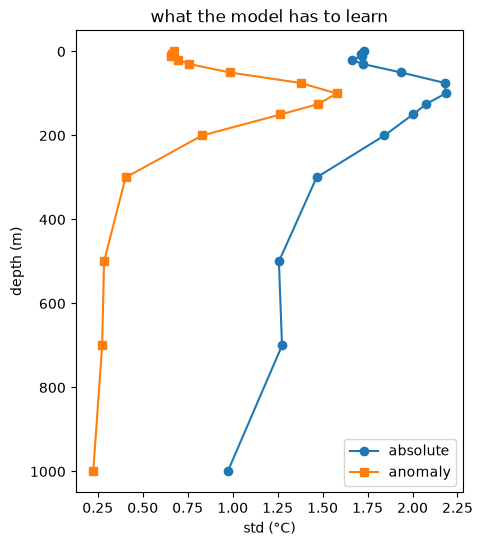

depth_m,0,5,10,20,30,50,75,100,125,150,200,300,500,700,1000
abs_std,1.73,1.71,1.72,1.66,1.73,1.94,2.18,2.18,2.08,2.00,1.84,1.47,1.26,1.27,0.97
anomaly_std,0.67,0.66,0.66,0.69,0.76,0.99,1.38,1.58,1.48,1.27,0.83,0.40,0.29,0.27,0.22


In [4]:
dep = load_yaml("grid.yaml")["depths"]
t = pd.DataFrame({"abs_std": [S["target_by_depth"][str(d)]["std"] for d in dep],
                  "anomaly_std": [S["anomaly_std_by_depth"][str(d)] for d in dep]}, index=pd.Index(dep, name="depth_m"))
plt.figure(figsize=(5,6)); plt.plot(t.abs_std, dep, "o-", label="absolute"); plt.plot(t.anomaly_std, dep, "s-", label="anomaly")
plt.gca().invert_yaxis(); plt.xlabel("std (°C)"); plt.ylabel("depth (m)"); plt.legend(); plt.title("what the model has to learn"); plt.show()
t.round(2).T

## Which surface variables carry information at which depth (Spearman, train days)

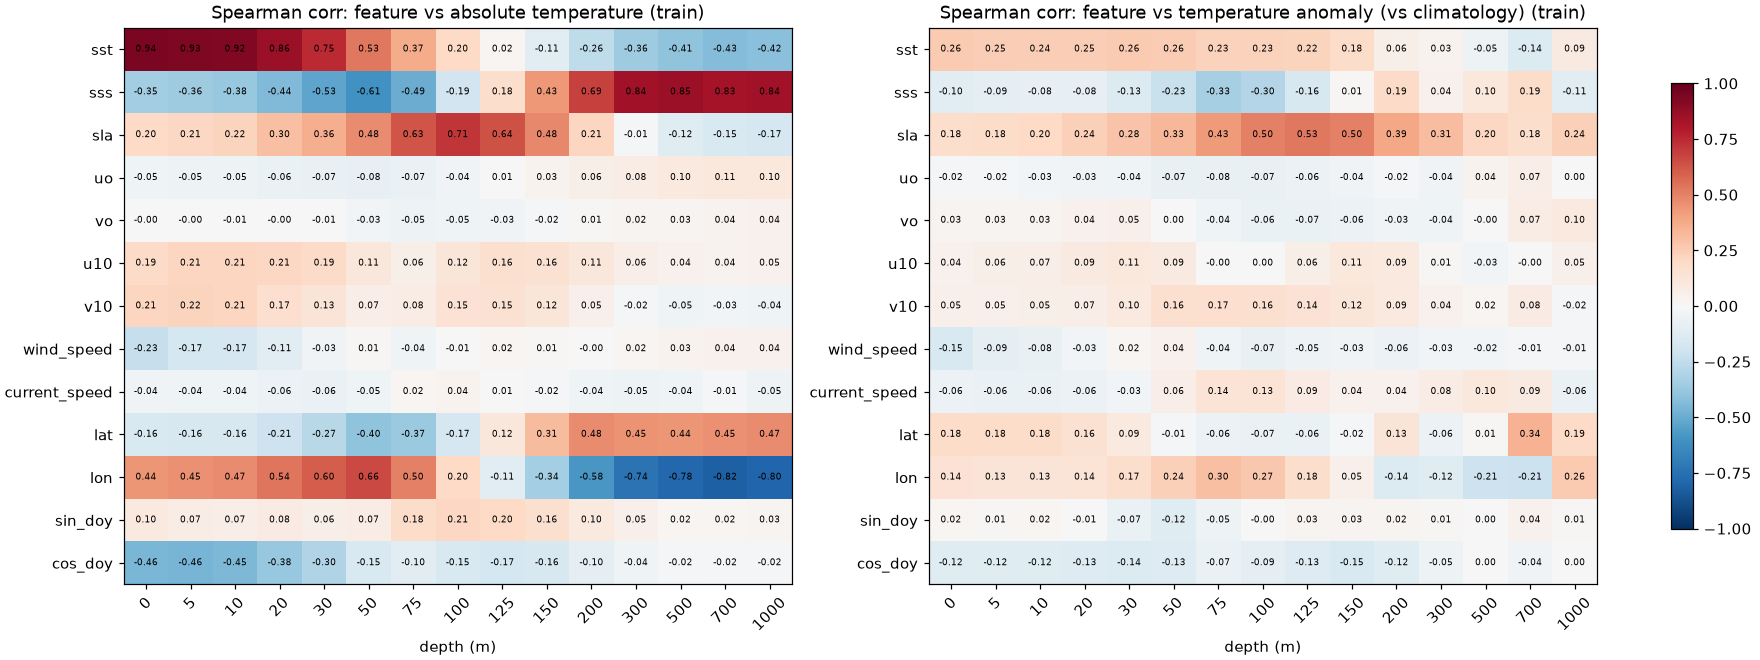

,0,50,100,150,300,1000
sla,0.18,0.33,0.50,0.50,0.31,0.24
sss,-0.10,-0.23,-0.30,0.01,0.04,-0.11
lon,0.14,0.24,0.27,0.05,-0.12,0.26
sst,0.26,0.26,0.23,0.18,0.03,0.09
v10,0.05,0.16,0.16,0.12,0.04,-0.02
current_speed,-0.06,0.06,0.14,0.04,0.08,-0.06
cos_doy,-0.12,-0.13,-0.09,-0.15,-0.05,0.00
lat,0.18,-0.01,-0.07,-0.02,-0.06,0.19
uo,-0.02,-0.07,-0.07,-0.04,-0.04,0.00
wind_speed,-0.16,0.04,-0.07,-0.03,-0.03,-0.01


In [5]:
display(Image(filename=str(FIGURES/"phase3"/"09_feature_target_corr_by_depth.png")))
a = pd.DataFrame(S["feature_target_spearman_train"]["anomaly"]).T
a[["0","50","100","150","300","1000"]].round(2).sort_values("100", key=abs, ascending=False)

## Vertical structure: PCA of anomaly profiles

components for 90%: 6 | for 95%: 7


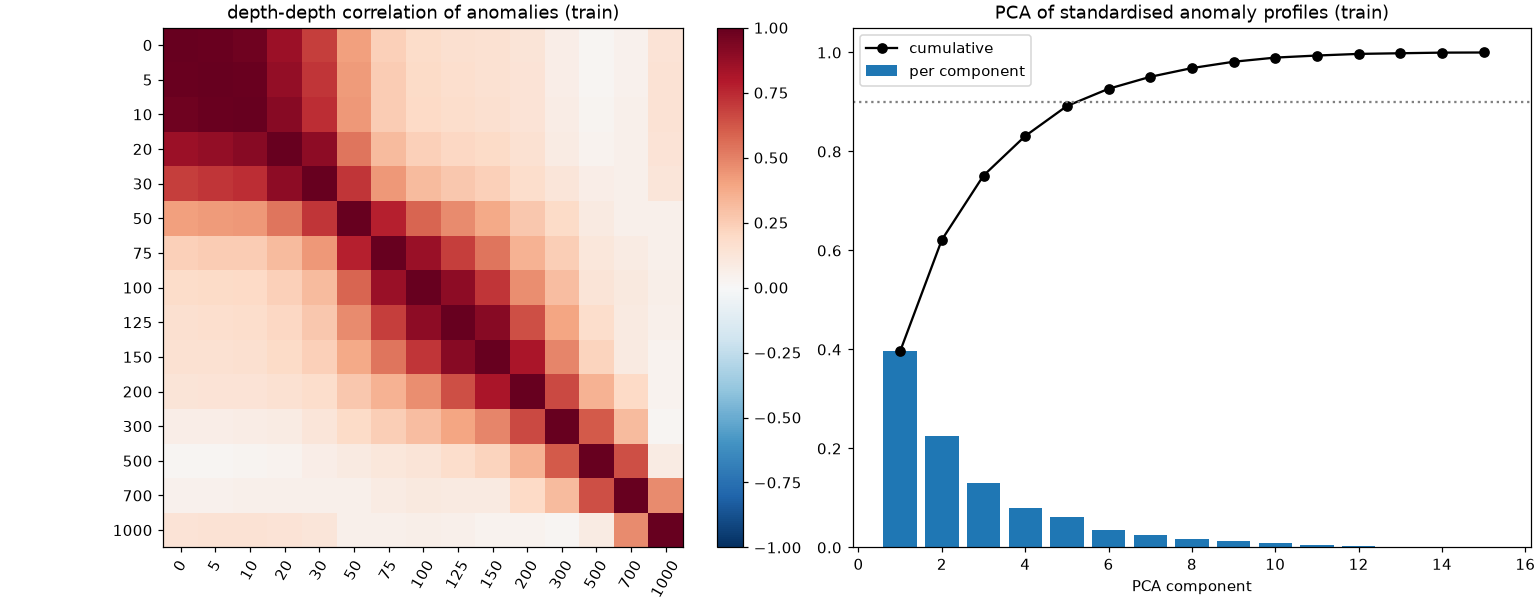

In [6]:
p = S["pca_anomaly_profiles_train"]
print("components for 90%:", p["n_components_90pct"], "| for 95%:", p["n_components_95pct"])
display(Image(filename=str(FIGURES/"phase3"/"10_depth_correlation_and_pca.png")))

## Regions, seasons, Hovmöller

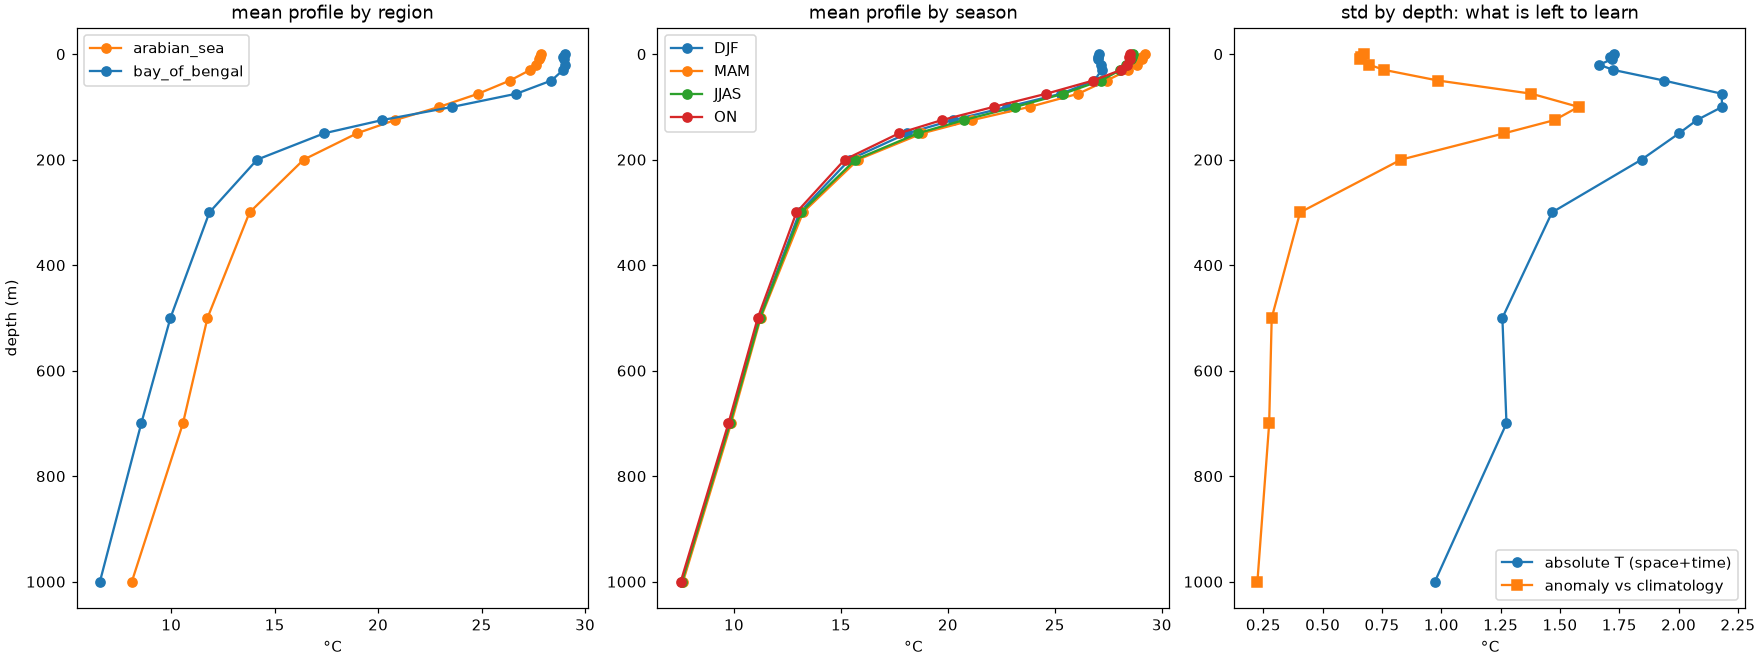

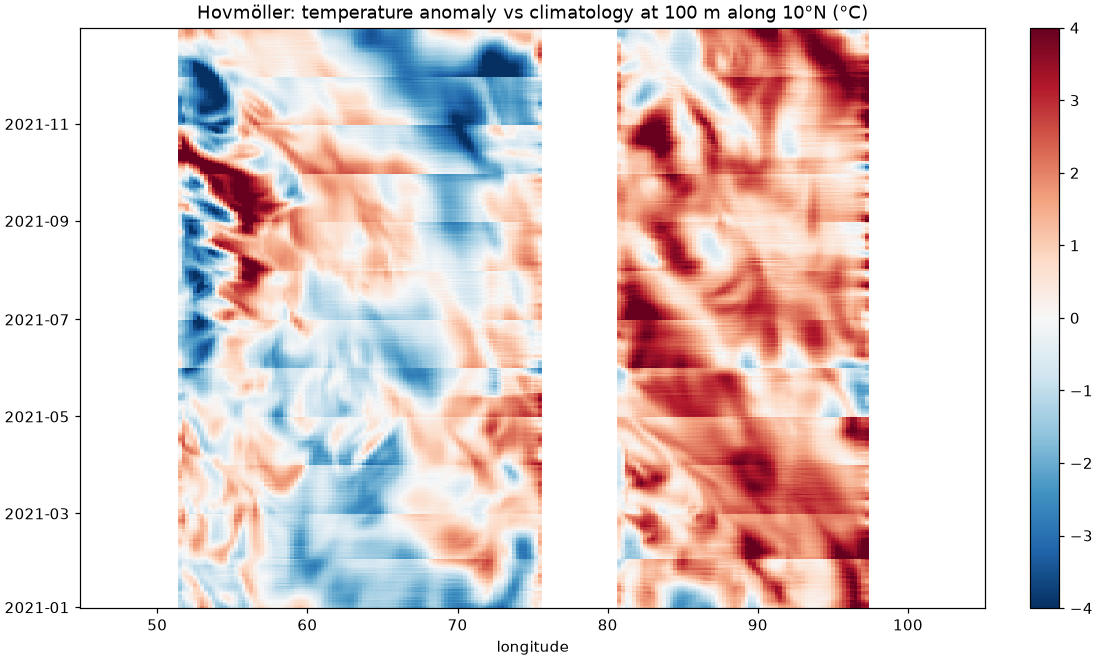

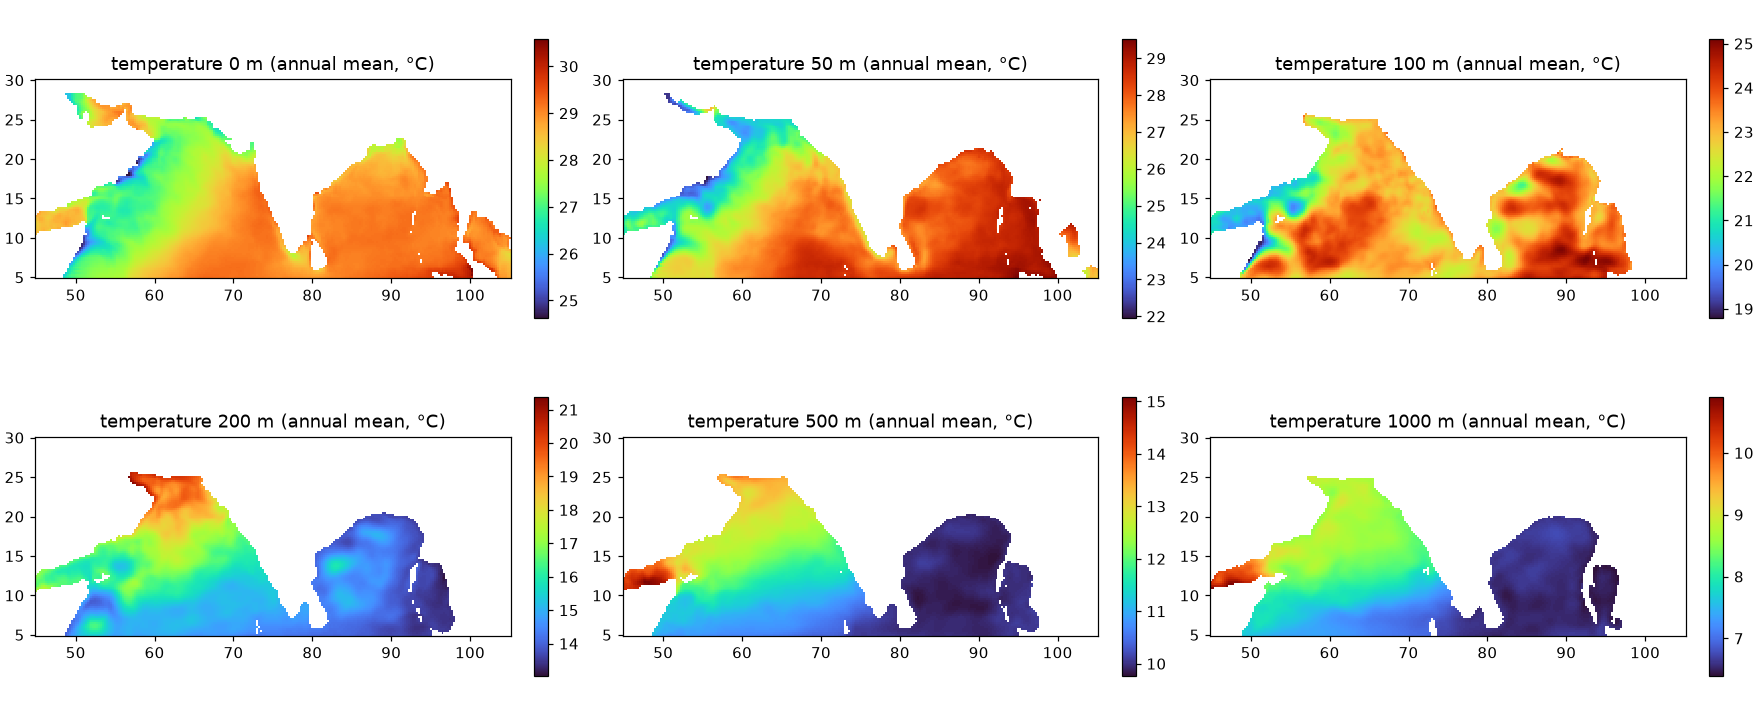

In [7]:
for f in ["07_profiles_region_season_variance.png","06_hovmoller_T100_anomaly_10N.png","02_target_mean_maps.png"]:
    display(Image(filename=str(FIGURES/"phase3"/f)))

## Outliers: measurement error or real event?

random ocean value near a cyclone: 0.029


,n_flagged,frac_of_ocean_values,frac_flags_near_cyclone_300km_7d,action
sst,909,0.00021,0.30253,kept (flag only)
sla,212,0.000049,0.0,kept (flag only)
sss,613,0.000142,0.011419,kept (flag only)


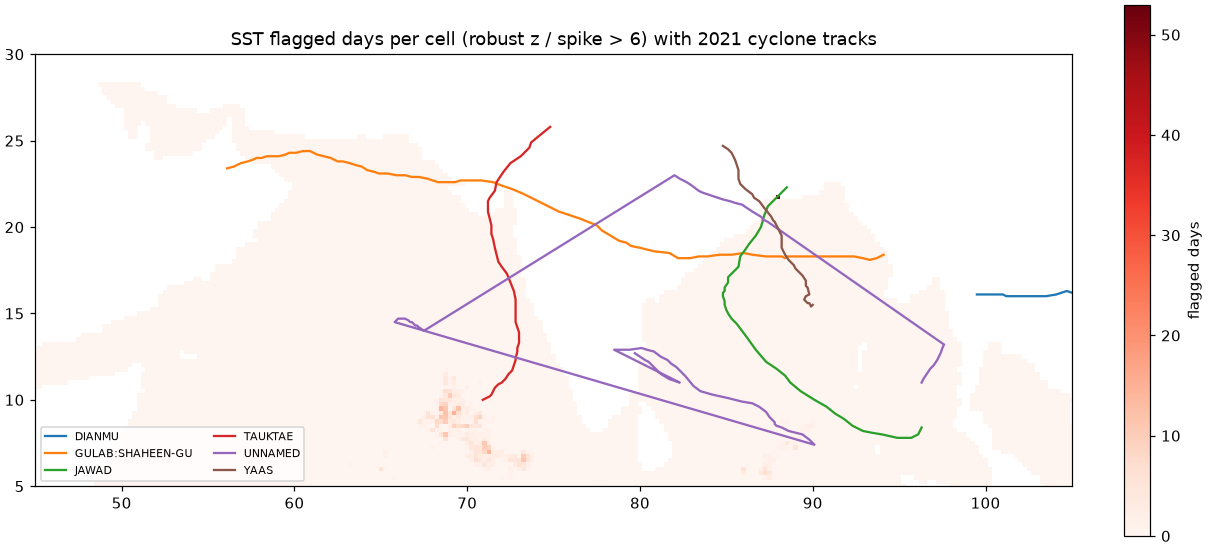

In [8]:
o = json.loads((AUDIT/"outlier_report.json").read_text())
print("random ocean value near a cyclone:", round(o["random_ocean_value_frac_near_cyclone"], 3))
display(pd.DataFrame(o["variables"]).T[["n_flagged","frac_of_ocean_values","frac_flags_near_cyclone_300km_7d","action"]])
display(Image(filename=str(FIGURES/"phase3"/"12_outliers_cyclones.png")))